In [1]:
# load the Preliminaries
import base64
import json
import re

import matplotlib
import matplotlib.category
import matplotlib.lines
import matplotlib.pyplot
import numpy
import pandas
import seaborn

In [2]:
import os
import sys

import django

PROJECT_ROOT = os.path.join(os.path.abspath(os.path.curdir), "djangosite")
DJANGO_SETTINGS_MODULE = "djangosite.settings"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
os.environ.setdefault("DJANGO_SETTINGS_MODULE", DJANGO_SETTINGS_MODULE)
# os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"
django.setup()

In [3]:
participant_df = pandas.read_parquet("djangosite/dumps/participant.parquet")
rule_df = pandas.read_parquet("djangosite/dumps/rule.parquet")
result_df = pandas.read_parquet("djangosite/dumps/result.parquet")
update_df = pandas.read_parquet("djangosite/dumps/update.parquet")
change_df = pandas.read_parquet("djangosite/dumps/change.parquet")

In [4]:
participant_df_msc = pandas.read_parquet("djangosite/dumps/msc/participant.parquet")
rule_df_msc = pandas.read_parquet("djangosite/dumps/msc/rule.parquet")
result_df_msc = pandas.read_parquet("djangosite/dumps/msc/result.parquet")
update_df_msc = pandas.read_parquet("djangosite/dumps/msc/update.parquet")
change_df_msc = pandas.read_parquet("djangosite/dumps/msc/change.parquet")

In [5]:
participant_df_pilot = pandas.read_parquet("djangosite/dumps/pilot/participant.parquet")
rule_df_pilot = pandas.read_parquet("djangosite/dumps/pilot/rule.parquet")
result_df_pilot = pandas.read_parquet("djangosite/dumps/pilot/result.parquet")
update_df_pilot = pandas.read_parquet("djangosite/dumps/pilot/update.parquet")
change_df_pilot = pandas.read_parquet("djangosite/dumps/pilot/change.parquet")
participant_df_pilot["Expert"] = participant_df_pilot.index.to_series().isin([9, 31, 16])

# Story 1: Identifying common areas for improvement of performance across all trainees

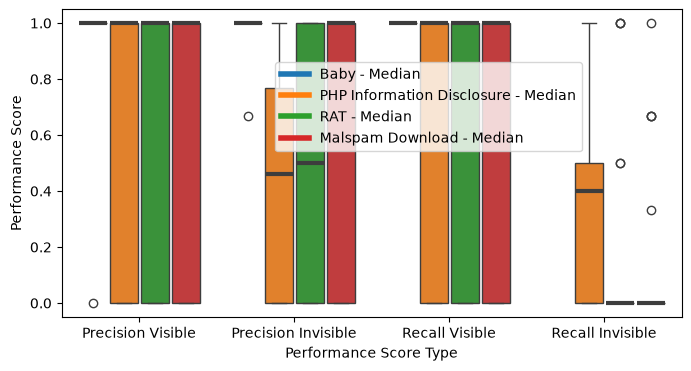

In [6]:
df = rule_df[(rule_df["Final Best Submission During CTF"])]
y_cols = ["Precision Visible", "Precision Invisible", "Recall Visible", "Recall Invisible"]

df = df.melt(id_vars=["Scenario", "User ID"], value_vars=y_cols, var_name="Performance Score Type", value_name="Performance Score")

for user_id in df["User ID"].unique():
    user_df = df[(df["User ID"] == user_id)]
    for scenario in df["Scenario"].unique():
        if scenario not in user_df["Scenario"].unique():
            df = pandas.concat([df,
                pandas.DataFrame(
                    [{
                        "Scenario": scenario,
                        "User ID": user_id,
                        "Performance Score Type": t,
                        "Performance Score": 0.
                    } for t in df["Performance Score Type"].unique()]
                )],
                ignore_index=True
            )

fig, ax = matplotlib.pyplot.subplots(figsize=(8, 4))

palette = seaborn.color_palette()

seaborn.boxplot(
    df, x="Performance Score Type", y="Performance Score", hue="Scenario",
    ax=ax,
    gap=0.1,
    medianprops={"linewidth": 3},
)

custom_lines = [
    matplotlib.lines.Line2D([0], [0], color=palette[i], lw=4)
    for i in range(df["Scenario"].nunique())
]
custom_labels = [f"{y_col} - Median" for y_col in df["Scenario"].unique()]
ax.legend(custom_lines, custom_labels, loc="upper right", bbox_to_anchor=(0.85, 0.85))

fig.savefig("figures/paper2/participant_pool_precision_recall.pdf", bbox_inches="tight", pad_inches=0, dpi=600)

C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\2175891480.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Result Numeric"] = df.apply(


RAT


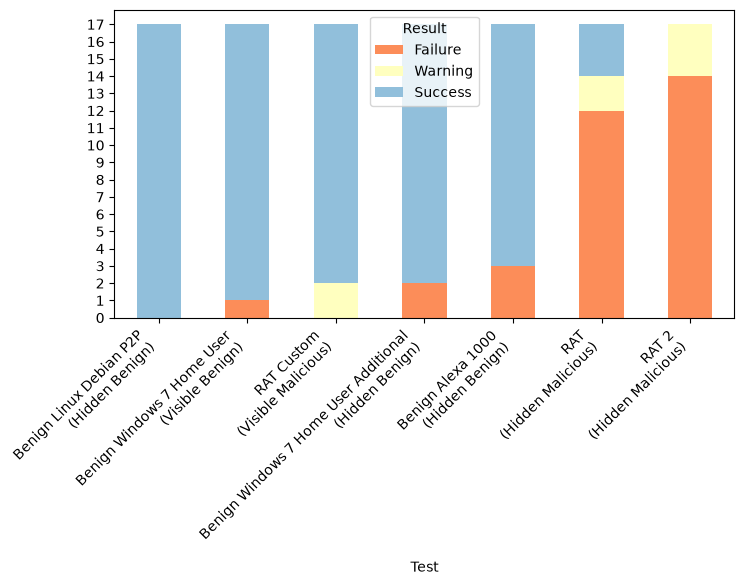

In [7]:
best_submissions = rule_df[(rule_df["Final Best Submission During CTF"])].index.to_list()
df = result_df[result_df["Rule ID"].apply(lambda x: x in best_submissions)]

df["Result Numeric"] = df.apply(
    lambda x: 2 if x["Result"] == "Success" else 0 if x["Result"] == "Failure" else 1, axis=1
)

# scenario = df["Scenario"].sample(1).to_numpy()[0]
scenario = "RAT"
print(scenario)

scenario_df = df[(df["Scenario"] == scenario)].sort_values(["Result Numeric", "Test Hidden", "Test Malicious", "Test"])

fig, ax = matplotlib.pyplot.subplots(figsize=(8, 4))

palette = seaborn.color_palette()

# seaborn.countplot(
#     scenario_df, hue="Result", x="Test",
#     ax=ax,
#     gap=0.1,
# )

plot_df = scenario_df.copy()
plot_df["Test"] = plot_df.apply(lambda row: row["Test"] + f"\n({'Hidden' if row['Test Hidden'] else 'Visible'} {'Malicious' if row['Test Malicious'] else 'Benign'})", axis=1)
plot_df = plot_df.groupby(["Test"])["Result"].value_counts().reset_index().pivot(index="Test", columns="Result", values="count").sort_values(["Success", "Warning", "Failure"], ascending=False)
plot_df = plot_df.loc[:, ["Failure", "Warning", "Success"]]

plot_df.plot.bar(
    color={"Failure": "#fc8d59", "Warning": "#ffffbf", "Success": "#91bfdb"},
    ax=ax,
    stacked=True,
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")

ax.set_yticks(range(scenario_df["User ID"].nunique() + 1))

fig.savefig("figures/paper2/participant_pool_rat_scenario_tests.pdf", bbox_inches="tight", pad_inches=0, dpi=600)

C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\1627493320.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  scenario_rule_df[desc] = scenario_rule_df["Design Principle Issues"].apply(lambda x: code in x)
C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\1627493320.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  scenario_rule_df[desc] = scenario_rule_df["Design Principle Issues"].apply(lambda x: code in x)
C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\1627493320.py:9: SettingWithCopyWar

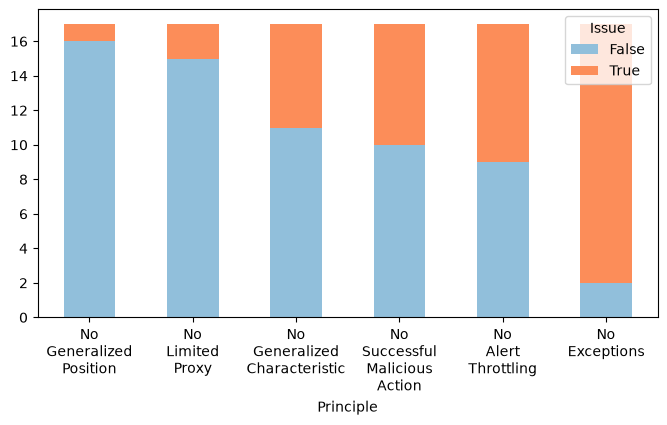

In [8]:
code_desc = {"Q000": "No Limited Proxy", "Q001": "No Successful Malicious Action", "Q002": "No Alert Throttling", "Q003": "No Exceptions", "Q004": "No Generalized Characteristic", "Q005": "No Generalized Position"}

x_col = "User ID"
y_cols = list(code_desc.values())

scenario_rule_df = rule_df[rule_df.apply(lambda row: int(row.name) in scenario_df["Rule ID"].astype(int).values, axis=1)]

for code, desc in code_desc.items():
    scenario_rule_df[desc] = scenario_rule_df["Design Principle Issues"].apply(lambda x: code in x)

fig, ax = matplotlib.pyplot.subplots(figsize=(8, 4))

plot_df = scenario_rule_df.reset_index().melt(id_vars=["Rule ID"], value_vars=code_desc.values(), var_name="Principle", value_name="Issue")
plot_df = plot_df.groupby(["Principle"])["Issue"].value_counts().reset_index().pivot(index="Principle", columns="Issue", values="count").sort_values([False, True], ascending=False)
plot_df.index = plot_df.index.str.replace(" ", "\n")

palette = seaborn.color_palette()

plot_df.plot.bar(
    color={True: "#fc8d59", False: "#91bfdb"},
    ax=ax,
    stacked=True,
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha="center")

fig.savefig("figures/paper2/participant_pool_rat_scenario_design_principles.pdf", bbox_inches="tight", pad_inches=0, dpi=600)

In [9]:
plot_df

Issue,False,True
Principle,,
No\nGeneralized\nPosition,16,1
No\nLimited\nProxy,15,2
No\nGeneralized\nCharacteristic,11,6
No\nSuccessful\nMalicious\nAction,10,7
No\nAlert\nThrottling,9,8
No\nExceptions,2,15


In [10]:
for rule in scenario_rule_df[scenario_rule_df.apply(lambda row: int(row.name) in scenario_rule_df[scenario_rule_df["No Generalized Characteristic"]].index.astype(int).values, axis=1)]["Rule"]:
    print(rule)
    print()

alert tls any any -> 23.94.236.147 any (msg:"RAT Custom"; threshold: type limit, track by_src, count 1, seconds 180; tls.version:0x0301; flow:established,to_server; sid:2;)

alert tls any any -> any any (msg: "Detected RAT communication"; sid: 1; content:"RAT";)

alert tls any any -> 23.94.236.147 any (msg:"greg"; sid:4; threshold: type limit, track by_src, seconds 180, count 1; tls.version:0x0301;)

alert tls any any -> 23.94.236.147 any (msg:"sus tls"; flow:to_server,established; threshold: type limit, track by_rule, count 1, seconds 2000; tls.version: 0x0301; sid:4;)


alert tls any any -> 23.94.236.147 any (msg:"sus tls"; threshold: type limit, track by_rule, count 1, seconds 2000; tls.version: 0x0301; sid:4;)

alert tls any any -> any any (msg:"match JA3 hash"; ja3.hash; content:"fc54e0d16d9764783542f0146a98b300"; sid:100001;)



## Additional insight on a different scenario focusing on specificity instead of coverage: 

PHP Information Disclosure


C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\1346955869.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Result Numeric"] = df.apply(


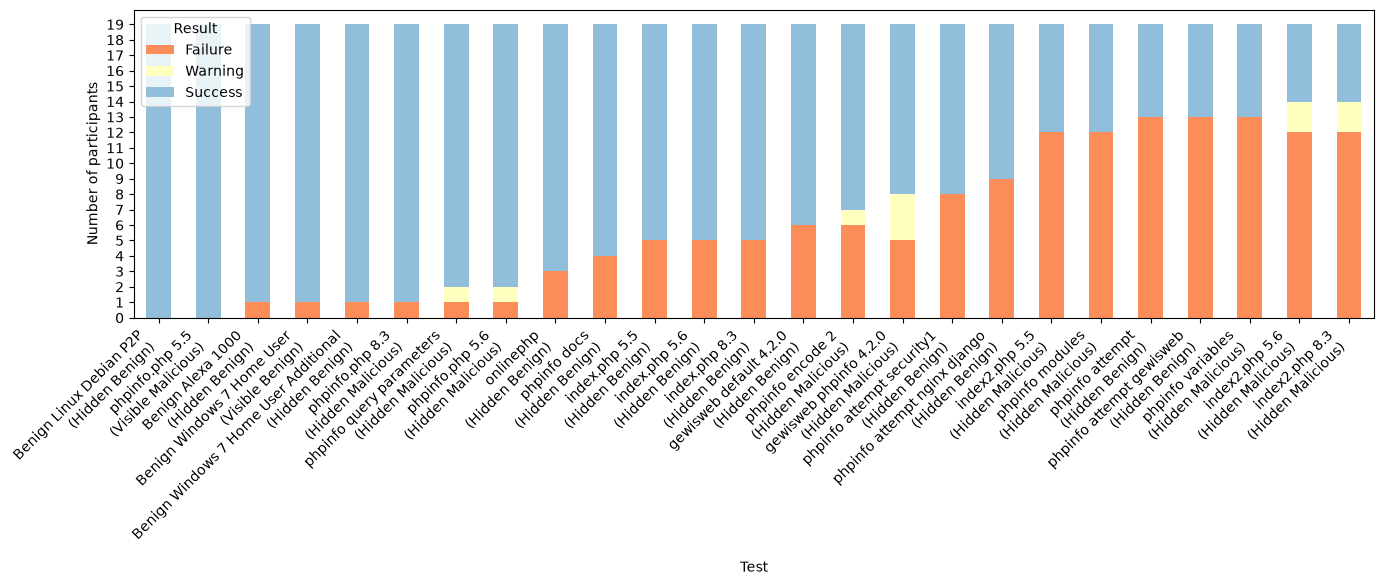

In [11]:
best_submissions = rule_df[(rule_df["Final Best Submission During CTF"])].index.to_list()
df = result_df[result_df["Rule ID"].apply(lambda x: x in best_submissions)]

df["Result Numeric"] = df.apply(
    lambda x: 2 if x["Result"] == "Success" else 0 if x["Result"] == "Failure" else 1, axis=1
)

# scenario = df["Scenario"].sample(1).to_numpy()[0]
scenario = "PHP Information Disclosure"
print(scenario)

scenario_df = df[(df["Scenario"] == scenario)].sort_values(["Result Numeric", "Test Hidden", "Test Malicious", "Test"])

fig, ax = matplotlib.pyplot.subplots(figsize=(16, 4))

palette = seaborn.color_palette()

# seaborn.countplot(
#     scenario_df, hue="Result", x="Test",
#     ax=ax,
#     gap=0.1,
# )

plot_df = scenario_df.copy()
plot_df["Test"] = plot_df.apply(lambda row: row["Test"] + f"\n({'Hidden' if row['Test Hidden'] else 'Visible'} {'Malicious' if row['Test Malicious'] else 'Benign'})", axis=1)
plot_df = plot_df.groupby(["Test"])["Result"].value_counts().reset_index().pivot(index="Test", columns="Result", values="count").sort_values(["Success", "Warning", "Failure"], ascending=False)
plot_df = plot_df.loc[:, ["Failure", "Warning", "Success"]]

plot_df.plot.bar(
    color={"Failure": "#fc8d59", "Warning": "#ffffbf", "Success": "#91bfdb"},
    ax=ax,
    stacked=True,
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")

ax.set_ylabel("Number of participants")
ax.set_yticks(range(scenario_df["User ID"].nunique() + 1))

fig.savefig("figures/paper2/participant_pool_phpinfo_scenario_tests.pdf", bbox_inches="tight", pad_inches=0, dpi=600)

C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\3355300800.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  scenario_rule_df[desc] = scenario_rule_df["Design Principle Issues"].apply(lambda x: code in x)
C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\3355300800.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  scenario_rule_df[desc] = scenario_rule_df["Design Principle Issues"].apply(lambda x: code in x)
C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\3355300800.py:9: SettingWithCopyWar

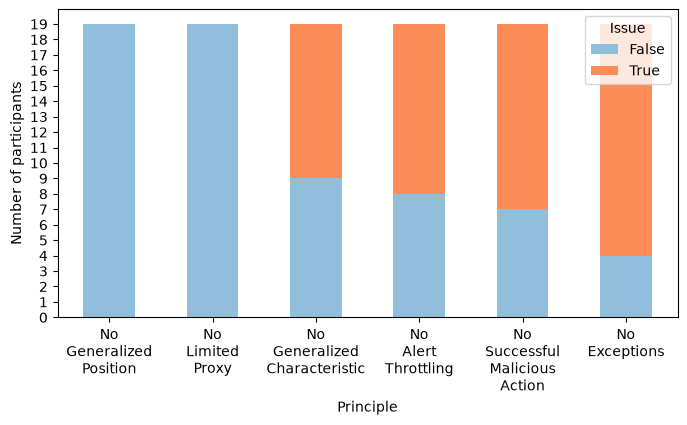

In [12]:
code_desc = {"Q000": "No Limited Proxy", "Q001": "No Successful Malicious Action", "Q002": "No Alert Throttling", "Q003": "No Exceptions", "Q004": "No Generalized Characteristic", "Q005": "No Generalized Position"}

x_col = "User ID"
y_cols = list(code_desc.values())

scenario_rule_df = rule_df[rule_df.apply(lambda row: int(row.name) in scenario_df["Rule ID"].astype(int).values, axis=1)]

for code, desc in code_desc.items():
    scenario_rule_df[desc] = scenario_rule_df["Design Principle Issues"].apply(lambda x: code in x)

fig, ax = matplotlib.pyplot.subplots(figsize=(8, 4))

plot_df = scenario_rule_df.reset_index().melt(id_vars=["Rule ID"], value_vars=code_desc.values(), var_name="Principle", value_name="Issue")
plot_df = plot_df.groupby(["Principle"])["Issue"].value_counts().reset_index().pivot(index="Principle", columns="Issue", values="count").sort_values([False, True], ascending=False)
plot_df.index = plot_df.index.str.replace(" ", "\n")

palette = seaborn.color_palette()

plot_df.plot.bar(
    color={True: "#fc8d59", False: "#91bfdb"},
    ax=ax,
    stacked=True,
)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha="center")

ax.set_ylabel("Number of participants")
ax.set_yticks(range(scenario_df["User ID"].nunique() + 1))

fig.savefig("figures/paper2/participant_pool_phpinfo_scenario_design_principles.pdf", bbox_inches="tight", pad_inches=0, dpi=600)

In [13]:
for rule in scenario_rule_df[scenario_rule_df.apply(lambda row: int(row.name) in scenario_rule_df[scenario_rule_df["No Successful Malicious Action"]].index.astype(int).values, axis=1)]["Rule"]:
    print(rule)
    print()

alert http $EXTERNAL_NET any -> $HOME_NET 80 (msg:"php"; sid: 124;  content: "/phpinfo.php"; http_uri; )

alert http any any -> any any (msg:"phpinfo() disclosure"; content:"/phpinfo.php"; threshold: type limit, track by_src, seconds 180, count 1; sid: 2; )


alert http any any -> any any (msg:"yash"; content: "http://ctf2.teuwen.net/phpinfo.php"; sid:1;)

alert http any any -> 84.25.5.41 80 (msg:"PHP Information Disclosure";    threshold:type limit, track by_src, count 1, seconds 180 ;sid:3;)

alert http any any -> any any (msg: "phpinfo() function detected"; threshold: type limit, track by_src, seconds 180, count 1; content:"phpinfo";sid:1;)

alert http $EXTERNAL_NET any -> $HOME_NET any (msg:"error";  uricontent:"/phpinfo.php"; threshold: type limit, track by_src, seconds 180, count 1; sid:1;)   

alert http any 80 -> any any (msg: "third rule"; flow:to_client, established; content: "php"; nocase; sid:2;)

alert http any any -> any any (msg:"Potential Info Leak - Access to phpinfo.p

In [14]:
best_submissions = rule_df[(rule_df["Final Best Submission During CTF"])].index.to_list()
df = result_df[result_df["Rule ID"].apply(lambda x: x in best_submissions)]

df["Result Numeric"] = df.apply(
    lambda x: 2 if x["Result"] == "Success" else 0 if x["Result"] == "Failure" else 1, axis=1
)

# scenario = df["Scenario"].sample(1).to_numpy()[0]
scenario = "PHP Information Disclosure"
print(scenario)

scenario_df = df[(df["Scenario"] == scenario)].sort_values(["Result Numeric", "Test Hidden", "Test Malicious", "Test"])

test = "phpinfo docs"
test = "phpinfo attempt"
print(test)

test_df = scenario_df[(scenario_df["Test"] == test)]

detections = []
for _, rule_row in test_df.iterrows():
    rule_id = rule_row["Rule ID"]
    rule = rule_df.loc[rule_id, "Rule"]
    user_id = rule_row["User ID"]
    scenario = rule_row["Scenario"]
    test = rule_row["Test"]

    for line in rule_row["Eve"].splitlines():
        parsed_line = json.loads(line)
        timestamp = parsed_line["timestamp"]
        src_ip = parsed_line["src_ip"]
        src_port = parsed_line["src_port"]
        dest_ip = parsed_line["dest_ip"]
        dest_port = parsed_line["dest_port"]
        proto = parsed_line["proto"]
        flow_start = parsed_line["flow"]["start"]
        flow_src_ip = parsed_line["flow"]["src_ip"]
        flow_src_port = parsed_line["flow"]["src_port"]
        flow_dest_ip = parsed_line["flow"]["dest_ip"]
        flow_dest_port = parsed_line["flow"]["dest_port"]
        payload = parsed_line["payload"]
        decoded_payload = base64.b64decode(payload).decode("utf-8")
        detections.append((rule_id, rule, user_id, scenario, test, timestamp, src_ip, src_port, dest_ip, dest_port, proto, flow_start, flow_src_ip, flow_src_port, flow_dest_ip, flow_dest_port, payload, decoded_payload))

detection_df = pandas.DataFrame(detections, columns=["Rule ID", "Rule", "User ID", "Scenario", "Test", "Timestamp", "Src IP", "Src Port", "Dest IP", "Dest Port", "Proto", "Flow Start", "Flow Src IP", "Flow Src Port", "Flow Dest IP", "Flow Dest Port", "Payload", "Decoded Payload"])
detection_df["Flow Tuple"] = detection_df.apply(lambda row: tuple(row[["Flow Start", "Proto", "Flow Src IP", "Flow Src Port", "Flow Dest IP", "Flow Dest Port"]]),axis=1)
detection_df["Timestamp"] = pandas.to_datetime(detection_df["Timestamp"])
detection_df["Flow Start"] = pandas.to_datetime(detection_df["Flow Start"])

counts = detection_df[["Flow Tuple", "Decoded Payload"]].value_counts()

print(counts)

print()
flow_tuple, decoded_payload = list(counts.items())[0][0]
for rule in detection_df.loc[(detection_df["Flow Tuple"] == flow_tuple) & (detection_df["Decoded Payload"] == decoded_payload)]["Rule"]:
    print(rule)
    print()


PHP Information Disclosure
phpinfo attempt
Flow Tuple                                                               Decoded Payload                                                                                                                                                                                                                                                                                                                                                                                                                                                                               
(2024-06-26T14:54:51.573959+0000, TCP, 10.8.0.7, 48722, 84.25.5.41, 80)  GET /phpinfo.php HTTP/1.1\r\nHost: phpinfo.teuwen.net\r\nUser-Agent: Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:127.0) Gecko/20100101 Firefox/127.0\r\nAccept: text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8\r\nAccept-Language: en-US,en;q=0.5\r\nAccept-Encoding: gzip, deflate\r\nDNT: 1\r\nSec

C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\2358978874.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Result Numeric"] = df.apply(


# Story 2: Identifying specific needs of individual trainees

INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


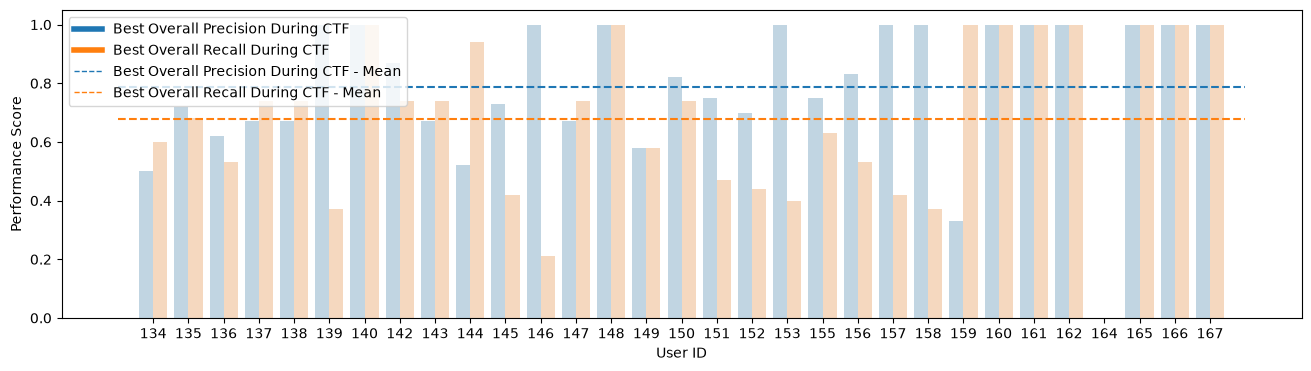

In [15]:
df = participant_df[participant_df["Participated"]]
x_col = "User ID"
y_cols = ["Best Overall Precision During CTF", "Best Overall Recall During CTF"]

fig, ax = matplotlib.pyplot.subplots(figsize=(16, 4))

# df[x_col] = [str(x) for x in range(len(df.index))]
df = df.reset_index()

palette = seaborn.color_palette()

df_plot = df.melt(id_vars=["User ID"], value_vars=y_cols, var_name="Performance Score Type", value_name="Performance Score")

seaborn.barplot(df_plot, x=x_col, y="Performance Score", hue="Performance Score Type", ax=ax, alpha=0.3)

for i, y_col in enumerate(y_cols):
    seaborn.lineplot(
        x=[-1, len(df.index)],
        y=df[y_col].mean(),
        ax=ax,
        color=palette[i],
        label=y_col + " - Median",
        linestyle="--"
    )

custom_lines = [
    matplotlib.lines.Line2D([0], [0], color=palette[i], lw=4)
    for i in range(len(y_cols))
] + [
    matplotlib.lines.Line2D([0], [0], color=palette[i], lw=1, linestyle="--")
    for i in range(len(y_cols))
]
custom_labels = y_cols + [f"{y_col} - Mean" for y_col in y_cols]
ax.legend(custom_lines, custom_labels)

fig.savefig("figures/paper2/individuals_precision_recall.pdf", bbox_inches="tight", pad_inches=0, dpi=600)

C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\3703680310.py:47: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df[x_col] = plot_df["Next Rule ID"].apply(lambda x: rule_df.loc[x, x_col])


alert tls any any -> any any (msg:"Potential RAT C2 Communication Detected"; tls.sni; content:"23.94.236.147"; nocase; flow:to_server,established; classtype:trojan-activity; sid:1000001; rev:1;)



alert tls any any -> any any (msg:"Potential RAT C2 Communication Detected"; tls.sni; content:"23.94.236.147"; nocase; flow:to_server,established; classtype:trojan-activity; sid:1000001; rev:1;)



alert tls any any -> any any (msg:"Potential RAT C2 Communication Detected"; tls.sni; content:"10.0.2.15"; nocase; flow:to_server,established; classtype:trojan-activity; sid:1000001; rev:1;)



alert tls any any -> any any (msg:"Potential RAT C2 Communication Detected"; tls.sni; content:"10.0.2.15"; nocase; flow:to_server,established; classtype:trojan-activity; sid:1000001; rev:1;)



alert tls any any -> any any (msg:"Potential RAT C2 Communication Detected"; tls.sni; content:"10.0.2.15"; nocase; sid:1000001; rev:1;)



alert tls any any -> any any (msg:"Potential RAT C2 Communication Detected"; 

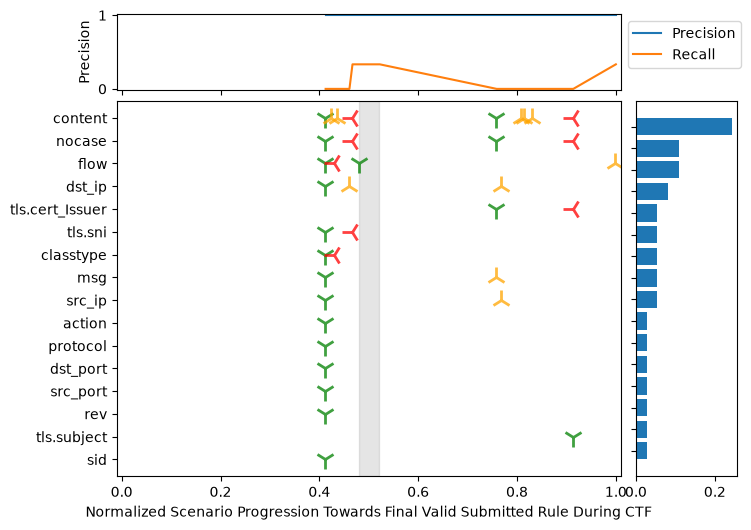

In [16]:
x_col = "Normalized Scenario Progression Towards Final Valid Submitted Rule During CTF"
y_cols = ["Precision", "Recall"]

# Struggled with interaction between protocol keyword and payload matching using content
# Suricata inspects the payload of the protocol specified in the header if no buffer is explicitly specified (so not the TLS headers if you specify TLS)
user_id = 155
scenario = "RAT"

# Le chat GPT?
user_id = 156
scenario = "RAT"

# Le chat GPT, rules that do not relate to traffic and change arbitrarily
user_id = 167
scenario = "RAT"

# Struggled finding the correct payload to match against, many content changes
user_id = 142
scenario = "PHP Information Disclosure"

# # Struggled with finding the correct characteristic to match against, many content changes and appliation layer protocol buffer changes
user_id = 136
scenario = "RAT"

fig, axs = matplotlib.pyplot.subplots(
    figsize=(8, 6),
    nrows=2,
    ncols=2,
    gridspec_kw={"width_ratios": [5, 1], "height_ratios": [1, 5], "wspace":0.05, "hspace":0.05},
    sharex=False,
    sharey=False,
)

axs[0, 1].remove()

mask = rule_df["Valid"] & rule_df["Submitted During CTF"]

extra_mask = rule_df["Scenario"] == scenario
extra_extra_mask = rule_df["User ID"] == user_id

# Plot performance on top
for y_col in y_cols:
    seaborn.lineplot(x=rule_df.loc[mask & extra_mask & extra_extra_mask, x_col], y=rule_df.loc[mask & extra_mask & extra_extra_mask, y_col], label=y_col, ax=axs[0, 0])

# Plot changes in the main window
plot_df = change_df[change_df["Next Rule ID"].apply(lambda x: x in rule_df.loc[mask & extra_mask & extra_extra_mask & (~rule_df["Multiple Rules"]), x_col].index)]
plot_df[x_col] = plot_df["Next Rule ID"].apply(lambda x: rule_df.loc[x, x_col])

str_category_converter = matplotlib.category.StrCategoryConverter()
change_freqs = plot_df["Field"].value_counts(normalize=True).sort_values()
unit_data = matplotlib.category.UnitData(change_freqs.index)
for i, row in plot_df.iterrows():
    color="black"
    marker = "."
    if row["Change Type"] == "Added":
        color = "green"
        marker="1"
    if row["Change Type"] == "Modified":
        color = "orange"
        marker="2"
    if row["Change Type"] == "Removed":
        color = "red"
        marker="3"

    # update = update_df[update_df["Changes"].apply(lambda x: str(row.name) in x.split(","))].iloc[0]
    # color="grey"
    # if (update["Change in Precision"] >= 0.0 and update["Change in Recall"] >= 0.0 and update["Change in F1"] != 0.0):
    #     color = "green"
    # if (update["Change in Precision"] <= 0.0 and update["Change in Recall"] <= 0.0 and update["Change in F1"] != 0.0):
    #     color = "red"
    # if (update["Change in Precision"] > 0.0 and update["Change in Recall"] < 0.0) or (update["Change in Precision"] < 0.0 and update["Change in Recall"] > 0.0):
    #     color = "orange"

    axs[1, 0].plot(row[x_col], str_category_converter.convert(row["Field"], unit=unit_data, axis=axs[1, 0]), marker=marker, markersize=15, markeredgewidth=2, markerfacecolor=color, markeredgecolor=color, alpha=0.75)

x0 = 0.
x1 = None
for i, row in rule_df.loc[mask & extra_mask & extra_extra_mask].iterrows():
    if row["Multiple Rules"]:
        if x1 is None:
            x1 = row[x_col]
    else:
        if x1 is not None:
            axs[1, 0].axvspan(x0, x1, color="grey", alpha=0.2)
            x1 = None
        x0 = row[x_col]

axisinfo = str_category_converter.axisinfo(unit_data, axs[1, 0])
axs[1, 0].yaxis.set_major_locator(axisinfo.majloc)
axs[1, 0].yaxis.set_major_formatter(axisinfo.majfmt)

# Plot density of changes on the side
axs[1, 1].yaxis.set_major_locator(axisinfo.majloc)
axs[1, 1].yaxis.set_major_formatter(axisinfo.majfmt)
axs[1, 1].barh(change_freqs.index, change_freqs.values)

# Limit x-axis
axs[0, 0].set_xlim(-0.01, 1.01)
axs[1, 0].set_xlim(-0.01, 1.01)

# Limit y-axis
axs[0, 0].set_ylim(-0.01, 1.01)

# Drop labels on the top right
axs[0, 0].set_xlabel(None)
axs[0, 0].set_xticklabels([])
axs[1, 1].set_yticklabels([])

# Set label on main plot
axs[1, 0].set_xlabel(x_col)

# Move legend
axs[0, 0].legend(loc="upper left", bbox_to_anchor=(1, 1))

for rule in rule_df.loc[mask & extra_mask & extra_extra_mask, "Rule"].values:
    print(rule)
    print()

fig.savefig(f"figures/paper2/participant_pool_{user_id}_{scenario}_process.pdf", bbox_inches="tight", pad_inches=0, dpi=600)

C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\1540826626.py:47: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df[x_col] = plot_df["Next Rule ID"].apply(lambda x: rule_df.loc[x, x_col])


alert tls any any -> any any (msg:"C2 RAT TLS connection detected";tls.sni; content:"suspicious.example.com"; nocase;sid:1000002; rev:1;)


alert tls any any -> any any (msg:"C2 RAT TLS connection detected";tls.sni; content:"suspicious.example.com"; nocase;sid:1000002; rev:1;)


alert tls any any -> any any (msg:"RAT C2 TLS connection detected via SNI";tls.sni; content:"suspicious.example.com"; nocase;sid:1000002; rev:1;)


alert tls any any -> any any (msg:"RAT C2 TLS connection detected via SNI";tls.sni; content:"suspicious.example.com"; nocase;sid:1000002; rev:1;)


alert tls any any -> any any (msg:"RAT C2 TLS connection detected via JA3 hash";ja3.hash; content:"e7eca2baf4458d095b7f45da28c16c34";sid:1000003; rev:1;)


alert tls any any -> any any (msg:"RAT C2 TLS connection detected via JA3 hash";ja3.hash; content:"e7eca2baf4458d095b7f45da28c16c34";sid:1000003; rev:1;)


alert tls any any -> any any (msg:"RAT C2 TLS connection detected via certificate subject";tls.cert_subject; con

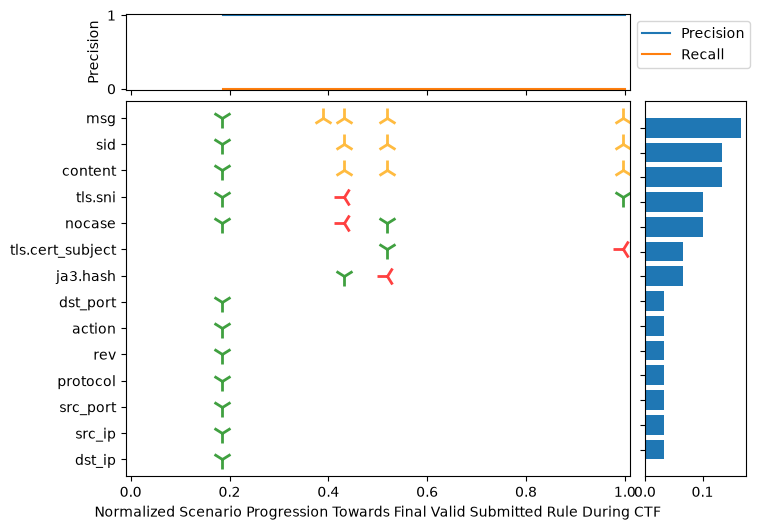

In [17]:
x_col = "Normalized Scenario Progression Towards Final Valid Submitted Rule During CTF"
y_cols = ["Precision", "Recall"]

# # Struggled with interaction between protocol keyword and payload matching using content
# # Suricata inspects the payload of the protocol specified in the header if no buffer is explicitly specified (so not the TLS headers if you specify TLS)
# user_id = 155
# scenario = "RAT"

# Le chat GPT?
user_id = 156
scenario = "RAT"

# Le chat GPT, rules that do not relate to traffic and change arbitrarily
user_id = 167
scenario = "RAT"

# # Struggled finding the correct payload to match against, many content changes
# user_id = 142
# scenario = "PHP Information Disclosure"

# # # Struggled with finding the correct characteristic to match against, many content changes and appliation layer protocol buffer changes
# user_id = 136
# scenario = "RAT"

fig, axs = matplotlib.pyplot.subplots(
    figsize=(8, 6),
    nrows=2,
    ncols=2,
    gridspec_kw={"width_ratios": [5, 1], "height_ratios": [1, 5], "wspace":0.05, "hspace":0.05},
    sharex=False,
    sharey=False,
)

axs[0, 1].remove()

mask = rule_df["Valid"] & rule_df["Submitted During CTF"]

extra_mask = rule_df["Scenario"] == scenario
extra_extra_mask = rule_df["User ID"] == user_id

# Plot performance on top
for y_col in y_cols:
    seaborn.lineplot(x=rule_df.loc[mask & extra_mask & extra_extra_mask, x_col], y=rule_df.loc[mask & extra_mask & extra_extra_mask, y_col], label=y_col, ax=axs[0, 0])

# Plot changes in the main window
plot_df = change_df[change_df["Next Rule ID"].apply(lambda x: x in rule_df.loc[mask & extra_mask & extra_extra_mask, x_col].index)]
plot_df[x_col] = plot_df["Next Rule ID"].apply(lambda x: rule_df.loc[x, x_col])

str_category_converter = matplotlib.category.StrCategoryConverter()
change_freqs = plot_df["Field"].value_counts(normalize=True).sort_values()
unit_data = matplotlib.category.UnitData(change_freqs.index)
for i, row in plot_df.iterrows():
    color="black"
    marker = "."
    if row["Change Type"] == "Added":
        color = "green"
        marker="1"
    if row["Change Type"] == "Modified":
        color = "orange"
        marker="2"
    if row["Change Type"] == "Removed":
        color = "red"
        marker="3"

    # update = update_df[update_df["Changes"].apply(lambda x: str(row.name) in x.split(","))].iloc[0]
    # color="grey"
    # if (update["Change in Precision"] >= 0.0 and update["Change in Recall"] >= 0.0 and update["Change in F1"] != 0.0):
    #     color = "green"
    # if (update["Change in Precision"] <= 0.0 and update["Change in Recall"] <= 0.0 and update["Change in F1"] != 0.0):
    #     color = "red"
    # if (update["Change in Precision"] > 0.0 and update["Change in Recall"] < 0.0) or (update["Change in Precision"] < 0.0 and update["Change in Recall"] > 0.0):
    #     color = "orange"

    axs[1, 0].plot(row[x_col], str_category_converter.convert(row["Field"], unit=unit_data, axis=axs[1, 0]), marker=marker, markersize=15, markeredgewidth=2, markerfacecolor=color, markeredgecolor=color, alpha=0.75)

axisinfo = str_category_converter.axisinfo(unit_data, axs[1, 0])
axs[1, 0].yaxis.set_major_locator(axisinfo.majloc)
axs[1, 0].yaxis.set_major_formatter(axisinfo.majfmt)

# Plot density of changes on the side
axs[1, 1].yaxis.set_major_locator(axisinfo.majloc)
axs[1, 1].yaxis.set_major_formatter(axisinfo.majfmt)
axs[1, 1].barh(change_freqs.index, change_freqs.values)

# Limit x-axis
axs[0, 0].set_xlim(-0.01, 1.01)
axs[1, 0].set_xlim(-0.01, 1.01)

# Limit y-axis
axs[0, 0].set_ylim(-0.01, 1.01)

# Drop labels on the top right
axs[0, 0].set_xlabel(None)
axs[0, 0].set_xticklabels([])
axs[1, 1].set_yticklabels([])

# Set label on main plot
axs[1, 0].set_xlabel(x_col)

# Move legend
axs[0, 0].legend(loc="upper left", bbox_to_anchor=(1, 1))

for rule in rule_df.loc[mask & extra_mask & extra_extra_mask, "Rule"].values:
    print(rule)
    print()

fig.savefig(f"figures/paper2/participant_pool_{user_id}_{scenario}_process.pdf", bbox_inches="tight", pad_inches=0, dpi=600)

## Expert

C:\Users\20173892\AppData\Local\Temp\ipykernel_15088\45057176.py:46: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df[x_col] = plot_df["Next Rule ID"].apply(lambda x: rule_df_pilot.loc[x, x_col])


alert http any any -> any any (msg: "That's a strange url"; sid: 3; http.response_body; content: "data:application/application/x-msdownload";)

alert http any any -> any any (msg: "That's a strange url"; sid: 3; http.response_body; content: "data:application/application/x-msdownload";)

alert http any any -> any any (msg: "That's a strange url"; sid: 3; http.response_body; content: "style=\"display:none\""; content: "href=\"data:application/application/x-msdownload";)

alert http any any -> any any (msg: "That's a strange url"; sid: 3; http.response_body; content: "style=\"display:none\""; content: "href=\"data:application/application/x-msdownload";)

alert http any any -> any any (msg: "That's a strange url"; sid: 3; http.response_body; content: "style=\"display:none\""; content: "href=\"data:application/application/x-msdownload"; content: "download=\"NFStock";)

alert http any any -> any any (msg: "That's a strange url"; sid: 3; http.response_body; content: "style=\"display:none\""; 

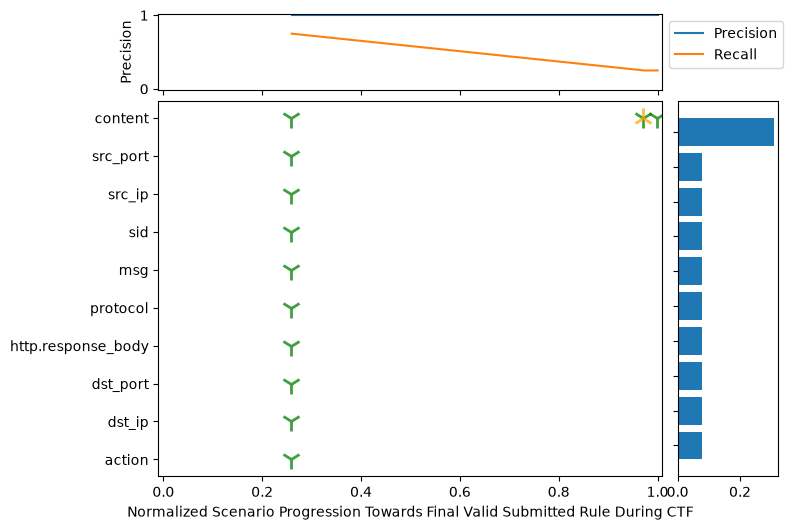

In [18]:
x_col = "Normalized Scenario Progression Towards Final Valid Submitted Rule During CTF"
y_cols = ["Precision", "Recall"]

# Frank struggled choosing the correct characteristic to match against, many content changes and application layer protocol buffer changes.
# The other users did not show any complicated processes towards their final rule, suggesting they knew more or less exactly what they were doing.
# user_id = 9
# # scenario = "Baby"
# # scenario = "PHP Information Disclosure"
# scenario = "Malspam Download"
# # scenario = "RAT"

# user_id = 13
# # scenario = "Baby"
# # scenario = "PHP Information Disclosure"
# # scenario = "Malspam Download"
# scenario = "RAT"

user_id = 16
# scenario = "Baby"
# scenario = "PHP Information Disclosure"
scenario = "Malspam Download"
# scenario = "RAT"

fig, axs = matplotlib.pyplot.subplots(
    figsize=(8, 6),
    nrows=2,
    ncols=2,
    gridspec_kw={"width_ratios": [5, 1], "height_ratios": [1, 5], "wspace":0.05, "hspace":0.05},
    sharex=False,
    sharey=False,
)

axs[0, 1].remove()

mask = rule_df_pilot["Valid"] & rule_df_pilot["Submitted During CTF"]

extra_mask = rule_df_pilot["Scenario"] == scenario
extra_extra_mask = rule_df_pilot["User ID"] == user_id

# Plot performance on top
for y_col in y_cols:
    seaborn.lineplot(x=rule_df_pilot.loc[mask & extra_mask & extra_extra_mask, x_col], y=rule_df_pilot.loc[mask & extra_mask & extra_extra_mask, y_col], label=y_col, ax=axs[0, 0])

# Plot changes in the main window
plot_df = change_df_pilot[change_df_pilot["Next Rule ID"].apply(lambda x: x in rule_df_pilot.loc[mask & extra_mask & extra_extra_mask, x_col].index)]
plot_df[x_col] = plot_df["Next Rule ID"].apply(lambda x: rule_df_pilot.loc[x, x_col])

str_category_converter = matplotlib.category.StrCategoryConverter()
change_freqs = plot_df["Field"].value_counts(normalize=True).sort_values()
unit_data = matplotlib.category.UnitData(change_freqs.index)
for i, row in plot_df.iterrows():
    color="black"
    marker = "."
    if row["Change Type"] == "Added":
        color = "green"
        marker="1"
    if row["Change Type"] == "Modified":
        color = "orange"
        marker="2"
    if row["Change Type"] == "Removed":
        color = "red"
        marker="3"

    # update = update_df[update_df["Changes"].apply(lambda x: str(row.name) in x.split(","))].iloc[0]
    # color="grey"
    # if (update["Change in Precision"] >= 0.0 and update["Change in Recall"] >= 0.0 and update["Change in F1"] != 0.0):
    #     color = "green"
    # if (update["Change in Precision"] <= 0.0 and update["Change in Recall"] <= 0.0 and update["Change in F1"] != 0.0):
    #     color = "red"
    # if (update["Change in Precision"] > 0.0 and update["Change in Recall"] < 0.0) or (update["Change in Precision"] < 0.0 and update["Change in Recall"] > 0.0):
    #     color = "orange"

    axs[1, 0].plot(row[x_col], str_category_converter.convert(row["Field"], unit=unit_data, axis=axs[1, 0]), marker=marker, markersize=15, markeredgewidth=2, markerfacecolor=color, markeredgecolor=color, alpha=0.75)

axisinfo = str_category_converter.axisinfo(unit_data, axs[1, 0])
axs[1, 0].yaxis.set_major_locator(axisinfo.majloc)
axs[1, 0].yaxis.set_major_formatter(axisinfo.majfmt)

# Plot density of changes on the side
axs[1, 1].yaxis.set_major_locator(axisinfo.majloc)
axs[1, 1].yaxis.set_major_formatter(axisinfo.majfmt)
axs[1, 1].barh(change_freqs.index, change_freqs.values)

# Limit x-axis
axs[0, 0].set_xlim(-0.01, 1.01)
axs[1, 0].set_xlim(-0.01, 1.01)

# Limit y-axis
axs[0, 0].set_ylim(-0.01, 1.01)

# Drop labels on the top right
axs[0, 0].set_xlabel(None)
axs[0, 0].set_xticklabels([])
axs[1, 1].set_yticklabels([])

# Set label on main plot
axs[1, 0].set_xlabel(x_col)

# Move legend
axs[0, 0].legend(loc="upper left", bbox_to_anchor=(1, 1))

for rule in rule_df_pilot.loc[mask & extra_mask & extra_extra_mask, "Rule"].values:
    print(rule)
    print()

fig.savefig(f"figures/paper2/participant_pool_{user_id}_{scenario}_process.pdf", bbox_inches="tight", pad_inches=0, dpi=600)